# Episode Detection and Classification

Detects hyperglycaemia episodes (glucose > 180 mg/dL) in each 45-day window and classifies them with six criteria (C1–C6) into **SLH** (short-lasting hyperglycaemia) or one of three other categories. The notebook uses the simplified classification of Figure 2 of the paper (`scripts/paper_figures/generate_figure_2_classification_summary.py`).

Equivalent script for the detection step: `python3 -m scripts.episodes_detection.episode_detection`.

**Usage** — from the repository root, point the notebook at a data folder and open it
(the 4-patient synthetic sample is enough: `make sample_data_run`):

```bash
CGM_DATA_ROOT=$PWD/sample_data jupyter lab notebooks/
```

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the **synthetic sample dataset** (`make sample_data`: fake patients A001–A004, simulated glucose, time expressed relative to an arbitrary t = 0). It contains **no real patient data**, and the numbers and figures are not expected to match the manuscript.

## The criteria

Detection finds every run of glucose above `H_HYPER` = 180 mg/dL. Six criteria are then evaluated on each episode
and stored as boolean columns `C1`…`C6`:

| Criterion | Rule |
|---|---|
| **C1** | Duration between `D_MIN_MIN` and `D_MAX_MIN` minutes |
| **C2** | Data completeness ≥ 75% around the episode |
| **C3** | Daytime: onset outside the night window (22:00–06:00) |
| **C4** | No hyperglycaemia in the 60 min before onset |
| **C5** | No hyperglycaemia in the 60 min after offset |
| **C6** | Glucose crosses ≤ 140 mg/dL (`H_CONTEXT`) before **or** after the episode |

## How to use C1–C6: the simplified approach

C4, C5 and C6 together describe whether the episode is **isolated** (normoglycaemia in the surrounding hour), so they are
used as one block, **context = C4 ∧ C5 ∧ C6**. The criteria are then applied in this order:

1. **Duration (C1)** — fails → **LLH** (long-lasting hyperglycaemia).
2. **Context (C4, C5, C6)** — fails → **Not isolated**.
3. **Data completeness (C2)** — episodes with too little data cannot be judged on context or daytime, so they are
   dropped before counting categories.
4. **Daytime (C3)** — evaluated **last**: fails → **Night** (would be SLH, but occurs at night); passes → **SLH**.

Daytime is a sub-classification of SLH, not a competing exclusion: an episode that is both non-isolated and at night is
**Not isolated**, not Night.

| Category | C1 | C4∧C5∧C6 | C3 |
|---|---|---|---|
| **LLH** | fails | – | – |
| **Not isolated** | passes | fails | – |
| **Night** | passes | passes | fails |
| **SLH** | passes | passes | passes |

The same rules drive the **waterfall** below, whose bars count the episodes that are still in the pool after each step.
Parameters live in `src/episodes/episode_config.py`.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import (
    PATIENT_ID_COL, TIME_COL, GLUCOSE_COL, COL_FILEPATH, WINDOW_SUMMARY_CSV,
    COL_EPISODE_START, COL_EPISODE_END, COL_EPISODE_DURATION, COL_EPISODE_CLASSIFICATION,
)
from src.preprocessing.load_data import load_window_data
from src.episodes.episode_config import (
    H_HYPER, H_CONTEXT, USE_GAP_MERGING, MERGE_GAP_MIN, MERGE_INTERNAL_GAP_MIN,
    D_MIN_MIN, D_MAX_MIN, MIN_DATA_COMPLETENESS, CONTEXT_WIN_MIN, NIGHT_START_H, NIGHT_END_H,
)
from src.episodes.load_episodes import prepare_episode_data, load_patient_episodes, load_episode_summary
from src.episodes.detection import detect_hyperglycemia_episodes
from src.episodes.criteria import classify_episodes
from src.visualization.colors import WONG_COLORS, COLOR_NIGHT_CATEGORY

%matplotlib inline

CATEGORY_ORDER = ["SLH", "Not isolated", "Night", "LLH"]
CATEGORY_COLORS = {
    "SLH": WONG_COLORS["orange"],
    "Not isolated": WONG_COLORS["reddish_purple"],
    "Night": COLOR_NIGHT_CATEGORY,
    "LLH": WONG_COLORS["blue"],
}

In [2]:
print(f"Detection threshold H_HYPER  : {H_HYPER} mg/dL")
print(f"Context threshold  H_CONTEXT : {H_CONTEXT} mg/dL")
print(f"C1 duration bounds           : {D_MIN_MIN}–{D_MAX_MIN} min")
print(f"C2 data completeness         : ≥ {MIN_DATA_COMPLETENESS:.0%}")
print(f"C3 night                     : {NIGHT_START_H:02d}:00–{NIGHT_END_H:02d}:00 excluded")
print(f"C4/C5 context window         : {CONTEXT_WIN_MIN} min")
print(f"Gap merging                  : {USE_GAP_MERGING} (gap ≤ {MERGE_GAP_MIN} min, internal gap ≤ {MERGE_INTERNAL_GAP_MIN} min)")

Detection threshold H_HYPER  : 180 mg/dL
Context threshold  H_CONTEXT : 140 mg/dL
C1 duration bounds           : 10–60 min
C2 data completeness         : ≥ 75%
C3 night                     : 22:00–06:00 excluded
C4/C5 context window         : 60 min
Gap merging                  : True (gap ≤ 30 min, internal gap ≤ 15 min)


## 2. Helpers: category and waterfall

`assign_category` applies the rules above to the `C1`…`C6` columns, and `waterfall_stats` counts the episodes remaining after each step.

In [3]:
def assign_category(episodes):
    """LLH / Not isolated / Night / SLH from the C1…C6 columns (daytime C3 is checked last)."""
    context = episodes["C4"] & episodes["C5"] & episodes["C6"]

    category = np.select(
        [~episodes["C1"], ~context, ~episodes["C3"]],
        ["LLH", "Not isolated", "Night"],
        default="SLH",
    )
    return episodes.assign(category=category)


def waterfall_stats(episodes):
    """Number of episodes left after each step: duration → context → completeness → daytime."""
    c1, c2, c3 = episodes["C1"], episodes["C2"], episodes["C3"]
    context = episodes["C4"] & episodes["C5"] & episodes["C6"]

    return [
        ("All hyperglycaemia episodes", len(episodes)),
        (f"Duration [{D_MIN_MIN:.0f}–{D_MAX_MIN:.0f} min]  (C1)", int(c1.sum())),
        ("Normoglycaemia in surrounding hour  (C4+C5+C6)", int((c1 & context).sum())),
        (f"Data completeness ≥{MIN_DATA_COMPLETENESS:.0%}  (C2)", int((c1 & context & c2).sum())),
        (f"Daytime {NIGHT_END_H:02d}:00–{NIGHT_START_H:02d}:00  (C3)  = SLH", int((c1 & context & c2 & c3).sum())),
    ]


def plot_waterfall(stats, title, ax=None):
    """Horizontal waterfall; each exclusion is coloured by the category those episodes join."""
    ax = ax or plt.subplots(figsize=(8, 3.4))[1]
    labels, values = zip(*stats)
    greys = ["#767676", "#8f8f8f", "#a8a8a8", "#c1c1c1"]
    colors = greys[:len(values) - 1] + [CATEGORY_COLORS["SLH"]]
    exclusion_colors = [None, CATEGORY_COLORS["LLH"], CATEGORY_COLORS["Not isolated"],
                        CATEGORY_COLORS["Not isolated"], CATEGORY_COLORS["Night"]]

    y = np.arange(len(values))[::-1]
    x_max = max(max(values), 1) * 1.45
    ax.barh(y, values, color=colors, height=0.55, edgecolor="white")
    for i, (yi, v) in enumerate(zip(y, values)):
        ax.text(v + x_max * 0.01, yi, f"n = {v:,}  ({v / max(values[0], 1):.0%})", va="center", fontsize=8)
        if i > 0 and values[i - 1] - v > 0:
            ax.text(v / 2, yi + 0.34, f"−{values[i - 1] - v:,}", ha="center", va="bottom",
                    fontsize=8, fontweight="bold", color=exclusion_colors[i])

    ax.set_xlim(0, x_max)
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Number of hyperglycaemia episodes")
    ax.set_title(title, fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    return ax

---
## 3. One patient, step by step

In [4]:
windows = pd.read_csv(WINDOW_SUMMARY_CSV)
row = windows.iloc[0]
patient_id = row[PATIENT_ID_COL]

df = prepare_episode_data(load_window_data(row[COL_FILEPATH]))
print(f"Patient {patient_id}: {len(df)} readings, {df[TIME_COL].min():%Y-%m-%d} → {df[TIME_COL].max():%Y-%m-%d}")

Patient A001: 12874 readings, 2000-01-01 → 2000-02-14


**Step 1 — detection.** Every run of glucose above 180 mg/dL is an episode (close runs are merged).

In [5]:
raw_episodes = detect_hyperglycemia_episodes(df)

print(f"{len(raw_episodes)} episodes detected")
pd.DataFrame(raw_episodes).head()

174 episodes detected


,onset_idx,offset_idx,onset_time,offset_time,duration_min,n_points,idx
0,90,102,2000-01-01 07:30:00,2000-01-01 08:30:00,65.0,13,"[90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, ..."
1,123,128,2000-01-01 10:15:00,2000-01-01 10:40:00,30.0,6,"[123, 124, 125, 126, 127, 128]"
2,146,153,2000-01-01 12:10:00,2000-01-01 12:45:00,40.0,8,"[146, 147, 148, 149, 150, 151, 152, 153]"
3,194,199,2000-01-01 16:10:00,2000-01-01 16:35:00,30.0,6,"[194, 195, 196, 197, 198, 199]"
4,228,231,2000-01-01 19:00:00,2000-01-01 19:15:00,20.0,4,"[228, 229, 230, 231]"


**Step 2 — criteria.** `classify_episodes` evaluates C1…C6 for every episode.

In [6]:
episodes = classify_episodes(df, raw_episodes)

episodes[[COL_EPISODE_START, COL_EPISODE_DURATION, "C1", "C2", "C3", "C4", "C5", "C6"]].head(10)

,onset_time,duration_min,C1,C2,C3,C4,C5,C6
0,2000-01-01 07:30:00,65.0,False,True,True,True,True,True
1,2000-01-01 10:15:00,30.0,True,True,True,True,True,True
2,2000-01-01 12:10:00,40.0,True,True,True,True,True,True
3,2000-01-01 16:10:00,30.0,True,True,True,True,True,True
4,2000-01-01 19:00:00,20.0,True,True,True,True,True,True
5,2000-01-02 07:05:00,50.0,True,True,True,True,True,True
6,2000-01-02 10:25:00,30.0,True,True,True,True,True,True
7,2000-01-02 11:55:00,45.0,True,True,True,True,True,True
8,2000-01-02 15:25:00,45.0,True,True,True,True,True,True
9,2000-01-03 06:45:00,60.0,True,True,True,True,True,True


**Step 3 — category.** Combine the criteria with the simplified rules.

In [7]:
episodes = assign_category(episodes)

print(episodes["category"].value_counts().reindex(CATEGORY_ORDER, fill_value=0).to_string())
episodes[[COL_EPISODE_START, COL_EPISODE_DURATION, "C1", "C3", "C4", "C5", "C6", "category"]].head(10)

category
SLH             149
Not isolated     15
Night             0
LLH              10


,onset_time,duration_min,C1,C3,C4,C5,C6,category
0,2000-01-01 07:30:00,65.0,False,True,True,True,True,LLH
1,2000-01-01 10:15:00,30.0,True,True,True,True,True,SLH
2,2000-01-01 12:10:00,40.0,True,True,True,True,True,SLH
3,2000-01-01 16:10:00,30.0,True,True,True,True,True,SLH
4,2000-01-01 19:00:00,20.0,True,True,True,True,True,SLH
5,2000-01-02 07:05:00,50.0,True,True,True,True,True,SLH
6,2000-01-02 10:25:00,30.0,True,True,True,True,True,SLH
7,2000-01-02 11:55:00,45.0,True,True,True,True,True,SLH
8,2000-01-02 15:25:00,45.0,True,True,True,True,True,SLH
9,2000-01-03 06:45:00,60.0,True,True,True,True,True,SLH


**Waterfall.** Episodes remaining after each step; the exclusions are coloured by the category they join.

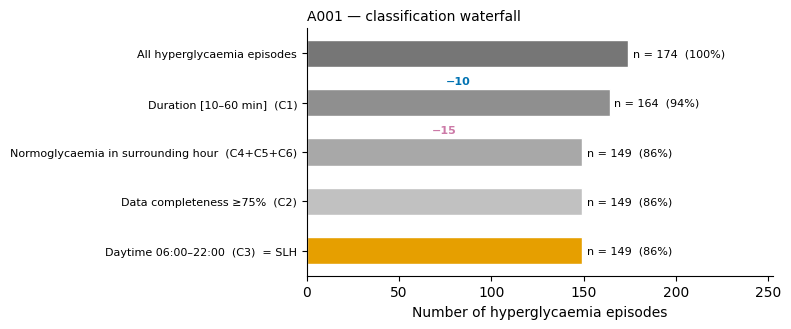

In [8]:
plot_waterfall(waterfall_stats(episodes), f"{patient_id} — classification waterfall")
plt.tight_layout()
plt.show()

**Result on the glucose trace.** Episodes are shaded by category (episodes failing C2 stay in the table, as in the waterfall).

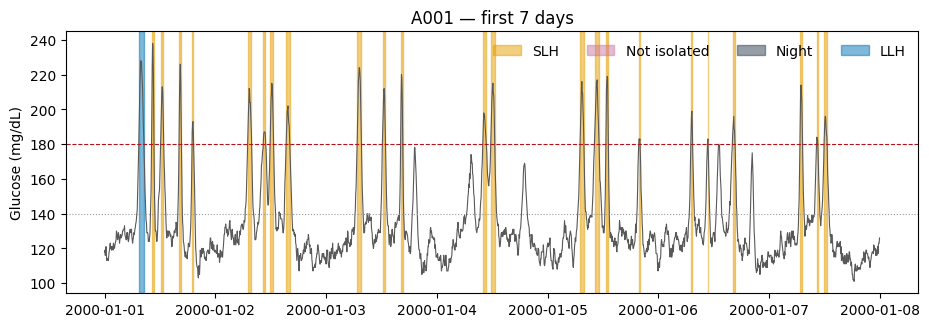

In [9]:
t0 = df[TIME_COL].min()
view = df[df[TIME_COL] < t0 + pd.Timedelta(days=7)]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(view[TIME_COL], view[GLUCOSE_COL], color="0.35", lw=0.8)
ax.axhline(H_HYPER, color="#B5121B", ls="--", lw=0.8)
ax.axhline(H_CONTEXT, color="0.6", ls=":", lw=0.8)

for _, ep in episodes.iterrows():
    if ep[COL_EPISODE_START] < view[TIME_COL].max():
        ax.axvspan(ep[COL_EPISODE_START], ep[COL_EPISODE_END], color=CATEGORY_COLORS[ep["category"]], alpha=0.5)

handles = [plt.Rectangle((0, 0), 1, 1, color=CATEGORY_COLORS[c], alpha=0.5, label=c) for c in CATEGORY_ORDER]
ax.legend(handles=handles, ncol=4, frameon=False, loc="upper right")
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title(f"{patient_id} — first 7 days")
plt.show()

---
## 4. Cohort

The pipeline writes one episode table per patient (`Data/Episodes/<patient>_episodes.csv`, with `C1`…`C6`) and a summary
with the number of SLH and LLH episodes per patient. The same helpers give the cohort waterfall.

  Loaded 4 patients from episodes summary


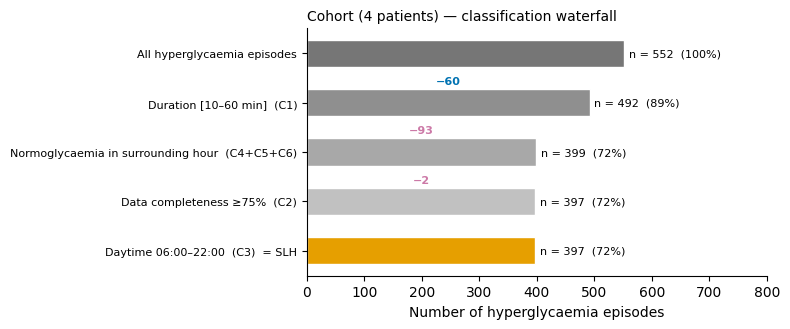

In [10]:
summary = load_episode_summary()
cohort = pd.concat(
    [load_patient_episodes(pid) for pid in summary[PATIENT_ID_COL]], ignore_index=True
)

plot_waterfall(waterfall_stats(cohort), f"Cohort ({summary[PATIENT_ID_COL].nunique()} patients) — classification waterfall")
plt.tight_layout()
plt.show()

### SLH and LLH episodes per patient

One bar per patient, sorted by number of SLH episodes, with the patient ID on the axis.
(`n_SLH` / `n_LLH` come from the pipeline's binary classification; the simplified categories are in the cohort table below.)

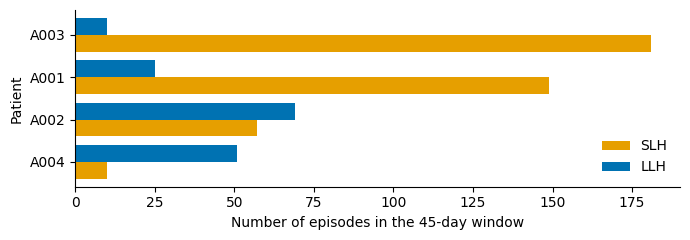

In [11]:
counts = summary.sort_values("n_SLH", ascending=True).reset_index(drop=True)
ids = counts[PATIENT_ID_COL].astype(str)
y = np.arange(len(counts))

fig, ax = plt.subplots(figsize=(7, max(2.5, 0.32 * len(counts) + 1)))
ax.barh(y - 0.2, counts["n_SLH"], height=0.4, color=CATEGORY_COLORS["SLH"], label="SLH")
ax.barh(y + 0.2, counts["n_LLH"], height=0.4, color=CATEGORY_COLORS["LLH"], label="LLH")

ax.set_yticks(y)
ax.set_yticklabels(ids)
ax.set_xlabel("Number of episodes in the 45-day window")
ax.set_ylabel("Patient")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Category composition per patient

In [12]:
cohort = assign_category(cohort[cohort["C2"]])           # C2 fails → dropped, as in the paper figure
composition = (cohort.groupby([PATIENT_ID_COL, "category"]).size()
                     .unstack(fill_value=0).reindex(columns=CATEGORY_ORDER, fill_value=0))
composition.loc[counts[PATIENT_ID_COL]]                  # same patient order as above

category,SLH,Not isolated,Night,LLH
patient_id,,,,
A004,10,40,0,11
A002,57,28,0,38
A001,149,14,0,10
A003,181,8,0,0
